# Анализ выборочного наблюдения труда мигрантов (2019)

Цель — сравнить продолжительность рабочей недели по миграционному статусу, возрасту, образованию, социальному статусу и федеральным округам.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

DATA_PATH = Path('data/itm_2019.csv')
assert DATA_PATH.exists(), f'Файл не найден: {DATA_PATH}'
pd.set_option('display.max_columns', 30)
plt.rcParams['figure.figsize'] = (9, 4.5)
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.2

## Загрузка данных


In [2]:
raw = pd.read_csv(DATA_PATH, sep=';', low_memory=False)
needed = ['GOD','MES','OKRYG_SV','NASOBRAZ','BB2','NAS_VOZR','mig_st','KATEG','RBVR_FOS']
assert set(needed).issubset(raw.columns)
work = raw.loc[pd.to_numeric(raw['RBVR_FOS'], errors='coerce') > 0, needed].copy()
print('Размер данных:', raw.shape)
print('После отбора:', work.shape)
print('Месяцы:', sorted(work.MES.unique().tolist()))
print('Годы:', sorted(work.GOD.unique().tolist()))
display(work.head())

Исходный файл: (308099, 52) | После фильтра: (160023, 9)
Месяцы: [4, 5, 8, 9]
Годы: [2019]


,GOD,MES,OKRYG_SV,NASOBRAZ,BB2,NAS_VOZR,mig_st,KATEG,RBVR_FOS
1,2019,8,1,3,4,53,2,6,42
2,2019,8,1,3,4,45,2,6,40
3,2019,8,1,3,4,24,2,6,40
4,2019,8,1,6,4,23,2,6,40
5,2019,8,1,3,2,50,2,6,40


## Описательная статистика


In [3]:
quant = ['NAS_VOZR','BB2','RBVR_FOS']
stats = work[quant].describe().T
stats['cv_pct'] = work[quant].std() / work[quant].mean() * 100
stats['skew'] = work[quant].skew()
stats['excess_kurtosis'] = work[quant].kurt()
display(stats.round(3))


,count,mean,std,min,25%,50%,75%,max,cv_pct,skew,excess_kurtosis
NAS_VOZR,160023.0,42.582,11.896,15.0,33.0,42.0,52.0,96.0,27.937,0.115,-0.672
BB2,160023.0,3.412,1.424,1.0,2.0,3.0,4.0,19.0,41.730,1.199,4.408
RBVR_FOS,160023.0,38.875,6.575,1.0,40.0,40.0,40.0,99.0,16.913,-1.368,13.257


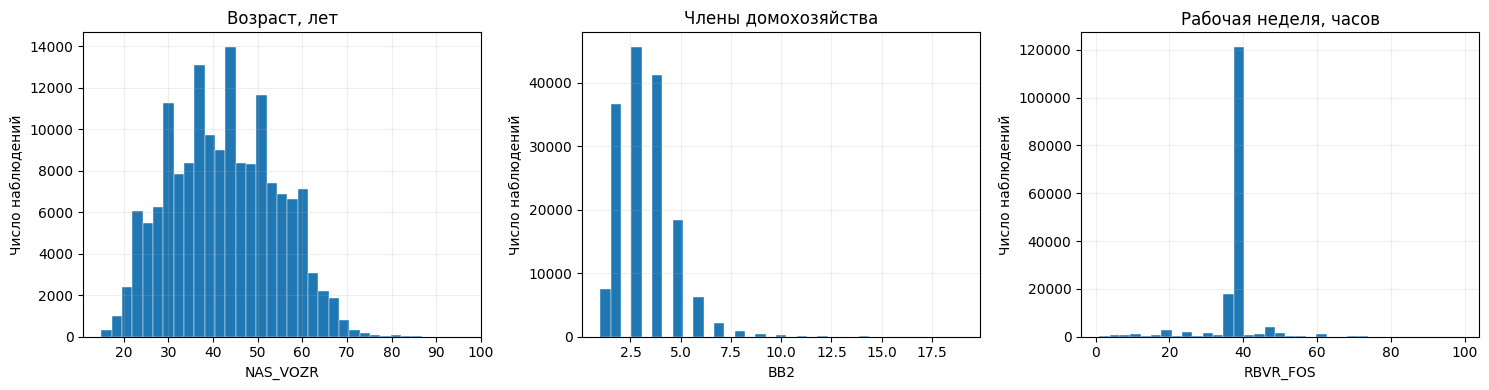

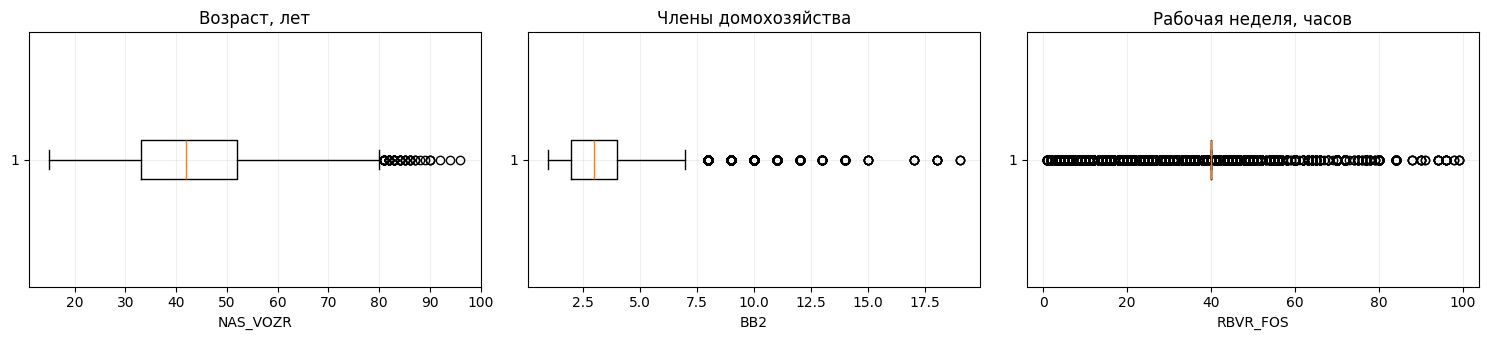

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, col, name in zip(ax, quant, ['Возраст, лет','Члены домохозяйства','Рабочая неделя, часов']):
    a.hist(work[col], bins=35, edgecolor='white', linewidth=.3)
    a.set(title=name, xlabel=col, ylabel='Число наблюдений')
plt.tight_layout(); plt.show()
fig, ax = plt.subplots(1, 3, figsize=(15, 3.5))
for a, col, name in zip(ax, quant, ['Возраст, лет','Члены домохозяйства','Рабочая неделя, часов']):
    a.boxplot(work[col], vert=False)
    a.set(title=name, xlabel=col)
plt.tight_layout(); plt.show()

## Группировка данных


In [5]:
def eta_squared(frame, group, target='RBVR_FOS'):
    t = frame[[group, target]].dropna()
    overall = t[target].mean()
    agg = t.groupby(group, observed=True)[target].agg(['mean', 'count'])
    between = ((agg['mean'] - overall)**2 * agg['count']).sum()
    total = ((t[target] - overall)**2).sum()
    eta2 = between / total if total else np.nan
    return np.sqrt(eta2), eta2

def group_summary(frame, col):
    out = frame.groupby(col, observed=True)['RBVR_FOS'].agg(['count','mean','median','std']).round(3)
    eta, eta2 = eta_squared(frame, col)
    print(f'{col}: η = {eta:.4f}, η² = {eta2:.4f} ({eta2*100:.2f}% вариации)')
    display(out)
    return out

# 1 — международные мигранты, 2 — остальные
status = group_summary(work, 'mig_st')
print('Разница средних (1 − 2):', round(status.loc[1,'mean']-status.loc[2,'mean'],3), 'ч')

mig_st: η = 0.0184, η² = 0.0003 (0.03% вариации)


,count,mean,median,std
mig_st,,,,
1,5274,39.530,40.0,7.464
2,154749,38.853,40.0,6.541


Разница средних (1 − 2): 0.677 ч


In [6]:
# Возрастные группы от 18 лет
work['age_group'] = pd.cut(work['NAS_VOZR'], bins=[17,25,35,45,np.inf],
                           labels=['18–25','26–35','36–45','46+'])
print('Не вошли в возрастную группировку (<18 лет):', work['age_group'].isna().sum())
age_summary = group_summary(work, 'age_group')

Не вошли в возрастную группировку (<18 лет): 339
age_group: η = 0.0814, η² = 0.0066 (0.66% вариации)


,count,mean,median,std
age_group,,,,
18–25,12353,38.403,40.0,7.499
26–35,36382,39.472,40.0,5.898
36–45,45818,39.397,40.0,5.552
46+,65131,38.370,40.0,7.121


In [7]:
# Группировка по образованию, социальному статусу и округу
for feature in ['NASOBRAZ','KATEG','OKRYG_SV']:
    group_summary(work, feature)

NASOBRAZ: η = 0.0951, η² = 0.0090 (0.90% вариации)


,count,mean,median,std
NASOBRAZ,,,,
1,43049,38.859,40.0,5.273
3,40860,38.976,40.0,5.755
4,32875,39.535,40.0,6.489
5,29397,38.578,40.0,7.948
6,7260,37.240,40.0,10.166
7,579,32.280,40.0,13.850
8,708,37.915,40.0,5.703
9,5295,38.876,40.0,5.823


KATEG: η = 0.2977, η² = 0.0886 (8.86% вариации)


,count,mean,median,std
KATEG,,,,
1,1042,23.780,20.0,13.585
2,20966,36.567,40.0,8.904
3,1033,33.758,40.0,12.145
5,828,23.816,21.0,14.238
6,136154,39.477,40.0,5.508


OKRYG_SV: η = 0.0725, η² = 0.0053 (0.53% вариации)


,count,mean,median,std
OKRYG_SV,,,,
1,44367,38.994,40.0,5.632
2,18191,38.824,40.0,5.937
3,15749,38.808,40.0,5.929
4,7416,36.871,40.0,9.235
5,29389,39.072,40.0,6.605
6,11333,39.233,40.0,6.215
7,18576,39.204,40.0,8.222
8,15002,38.586,40.0,6.690


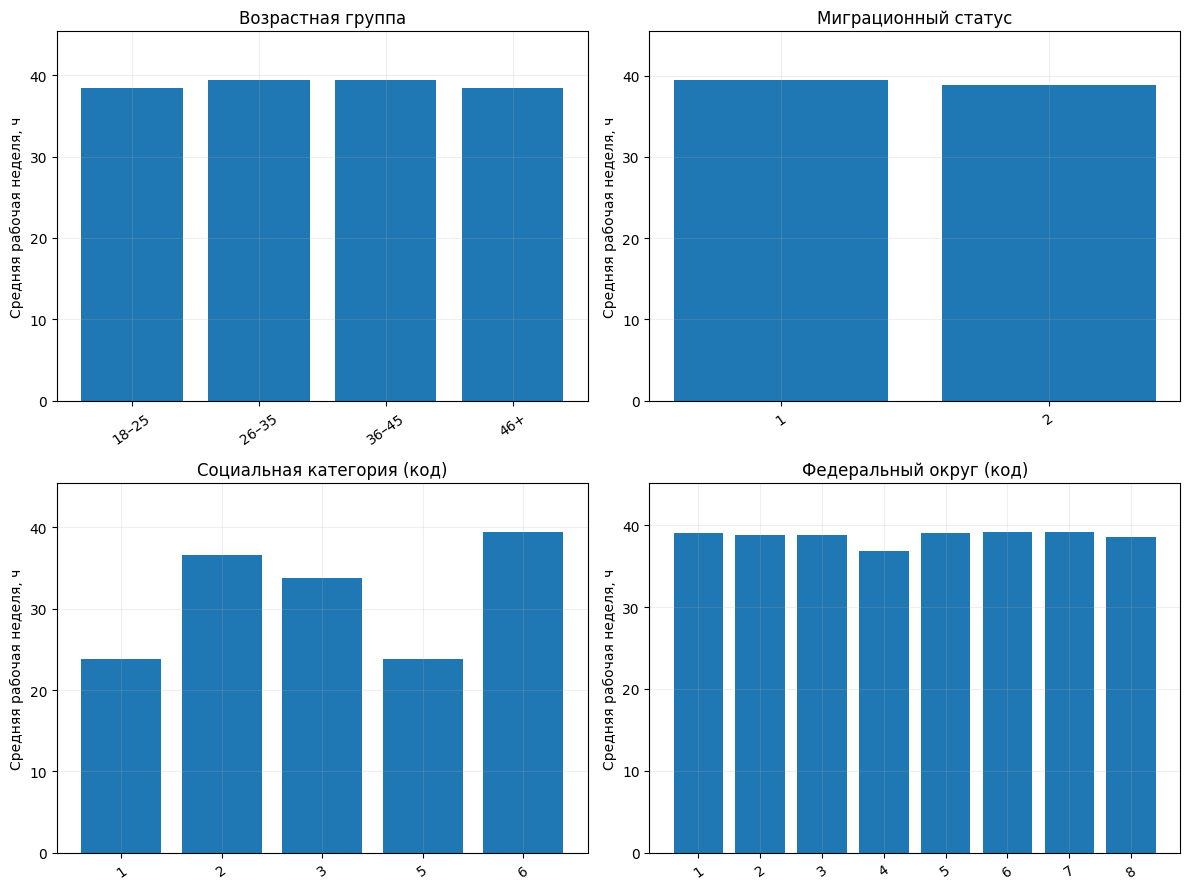

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
for ax, col, title in zip(axes.flat,
                          ['age_group','mig_st','KATEG','OKRYG_SV'],
                          ['Возрастная группа','Миграционный статус','Социальная категория (код)','Федеральный округ (код)']):
    means = work.groupby(col, observed=True)['RBVR_FOS'].mean()
    ax.bar(means.index.astype(str), means.values)
    ax.set(title=title, ylabel='Средняя рабочая неделя, ч')
    ax.tick_params(axis='x', rotation=35)
    ax.set_ylim(0, max(means.values)*1.15)
plt.tight_layout(); plt.show()

## Сравнение по миграционному статусу


In [9]:
from scipy.stats import ttest_ind
migrant = work.loc[work.mig_st == 1, 'RBVR_FOS']
other = work.loc[work.mig_st == 2, 'RBVR_FOS']
res = ttest_ind(migrant, other, equal_var=False)
print('Welch t-test (без учёта дизайна): t =', round(res.statistic,3),
      'p =', f'{res.pvalue:.3g}')
print('Разница средних:', round(migrant.mean()-other.mean(), 3), 'часа')
print('η² миграционного статуса:', round(eta_squared(work,'mig_st')[1],6))

Welch t-test (без учёта дизайна): t = 6.499 p = 8.79e-11
Разница средних: 0.677 часа
η² миграционного статуса: 0.000338


## Анализ по месяцам опроса


,n,avg_hours,avg_age
MES,,,
4,40175,38.939,42.630
5,40202,38.617,42.601
8,39411,38.899,42.376
9,40235,39.046,42.716


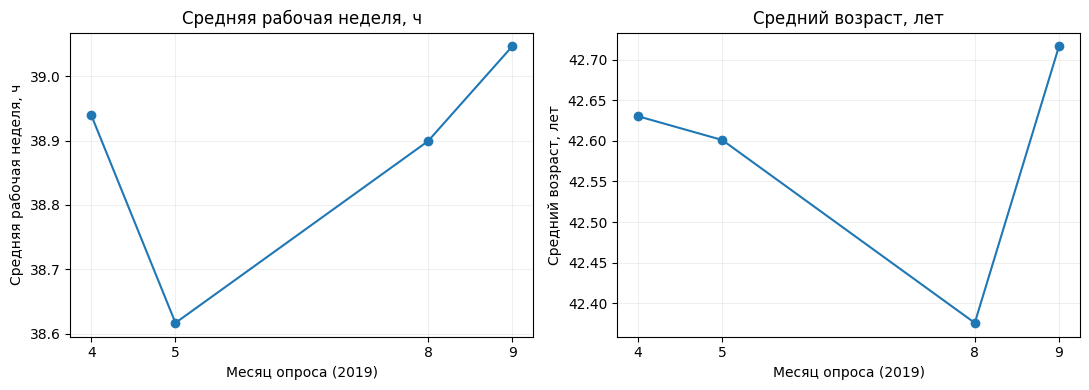

In [10]:
monthly = work.groupby('MES').agg(n=('RBVR_FOS','size'),
                                   avg_hours=('RBVR_FOS','mean'),
                                   avg_age=('NAS_VOZR','mean'))
display(monthly.round(3))
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for a, col, title in zip(axes, ['avg_hours','avg_age'],
                         ['Средняя рабочая неделя, ч','Средний возраст, лет']):
    a.plot(monthly.index, monthly[col], marker='o')
    a.set(xticks=monthly.index, xlabel='Месяц опроса (2019)', ylabel=title, title=title)
plt.tight_layout(); plt.show()

## Выводы

- После отбора записей с `RBVR_FOS > 0` осталось 160 023 наблюдения.
- Средняя рабочая неделя — 38,88 часа. У международных мигрантов — 39,53 часа, у остальных — 38,85 часа.
- По миграционному статусу разница средних — около 0,68 часа; η² ≈ 0,00034.
- Среди рассмотренных признаков наиболее заметные различия по средним связаны с социальной категорией (`KATEG`): η² ≈ 0,0886.
- Данные за 2019 год содержат апрель, май, август и сентябрь.

*Расчёты приведены без выборочных весов; результаты описывают данный массив, а не всё население.*
